In [1]:
# Explicabilité SHAP sur le modèle de référence (03, colonnes complètes) :
# comprendre CE QUE le modèle a appris, globalement et prédiction par prédiction.
# On reconstruit le modèle à l'identique — même pipeline que 03.
import pandas as pd

In [2]:
df = pd.read_csv("data/train_transaction.csv")

In [3]:
id_df = pd.read_csv('data/train_identity.csv')
id_df.shape

(144233, 41)

In [4]:
# Jointure gauche : on garde les 76 % de transactions sans identity (leur absence est un signal, cf. 01).
# 590 540 x 434 : mêmes shapes que dans 02. 

df = df.merge(id_df, on='TransactionID', how='left')
df.shape

(590540, 434)

In [5]:
#Détermination de la proportion de transaction à + de 2 décimales
#round(2) écrase la poussière binaire (12ᵉ décimale) et garde intact le signal (la vraie 3ᵉ décimale, qui vit à la 1ʳᵉ décimale après le × 100). N'importe quel n entre 1 et 9 marchait.

has_3dec = (df['TransactionAmt'] * 100).round(2) % 1 != 0
has_3dec.mean()

np.float64(0.10487519897043383)

In [6]:
# Structure temporelle : TransactionDT = compteur de secondes depuis une référence inconnue.
# // 3600 -> heures entières écoulées ; % 24 -> position dans le cycle de la journée (0-23).
# NB : rien ne dit que l'heure 0 = minuit (référence inconnue) — sans conséquence pour le
# modèle, le cycle reste cohérent d'un bout à l'autre du dataset.

hour = (df['TransactionDT'] // 3600) % 24

In [7]:
# Construction des features validées : une mesure ne devient un signal pour le modèle
# que si elle existe comme colonne de df (le modèle ne voit que les colonnes de X).
# astype(int) : les sélections numériques (select_dtypes) ignorent silencieusement les booléens.
df['has_3dec'] = has_3dec.astype(int)
df['hour'] = hour

C:\Users\gueuj\AppData\Local\Temp\ipykernel_5556\2805609261.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['has_3dec'] = has_3dec.astype(int)
C:\Users\gueuj\AppData\Local\Temp\ipykernel_5556\2805609261.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['hour'] = hour


In [8]:
df.shape

(590540, 436)

In [9]:
#séparation indices/réponses : X = les features, y = la cible.

X = df.drop(columns=['isFraud', 'TransactionID'])
y = df['isFraud']

In [10]:
#Conversion des colonnes texte pour XGBoost
for col in X.select_dtypes(exclude='number').columns:
    X[col] = X[col].astype('category')

In [11]:
# Split temporel 80/20 

cut = int(len(X) * 0.8)
X_train, X_valid = X.iloc[:cut], X.iloc[cut:]
y_train, y_valid = y.iloc[:cut], y.iloc[cut:]
X_train.shape, X_valid.shape

((472432, 434), (118108, 434))

In [12]:
# Modèle de référence 03 : référence à battre
from xgboost import XGBClassifier

model = XGBClassifier(
    n_estimators=300,
    tree_method='hist',
    enable_categorical=True,
    eval_metric='aucpr',
    n_jobs=-1,
    random_state=42,
)
model.fit(X_train, y_train)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'aucpr'
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [13]:
#Eval sur le futur
from sklearn.metrics import average_precision_score

probs = model.predict_proba(X_valid)[:, 1]
average_precision_score(y_valid, probs)

0.5120140134801691

In [14]:
# Points de fonctionnement : pour un recall visé, quel seuil et quelle precision ?
from sklearn.metrics import precision_recall_curve
import numpy as np

precision, recall, thresholds = precision_recall_curve(y_valid, probs)

i = np.argmin(np.abs(recall - 0.5))
thresholds[i], precision[i], recall[i]

(np.float32(0.15065287), np.float64(0.5132609244758778), np.float64(0.5))

In [15]:
#seuil optimal en coût
P = y_valid.sum() #total des fraudes. Egalement égal à : TP+FN
FN = P * (1 - recall) #recall = TP/(TP+FN)
FP = P * recall * (1 - precision)/precision #precision = TP/(TP+FP)
cost = 100 * FN + 5 * FP #coût métier : -100 pour une fraude ratée ; -5 pour un client bloqué à tort 

i_cost = np.argmin(cost)
thresholds[i_cost], cost[i_cost], precision[i_cost], recall[i_cost]

(np.float32(0.02476302),
 np.float64(166230.0),
 np.float64(0.20740482011875655),
 np.float64(0.7305610236220472))

In [16]:
# Échantillon de la validation : TreeExplainer est exact mais coûteux (une passe
# par arbre et par ligne) ; 5 000 lignes suffisent pour la vue globale.
X_sample = X_valid.sample(5000, random_state=42)

In [17]:
import shap
explainer = shap.TreeExplainer(model)
sv = explainer(X_sample)

In [18]:
sv.shape

(5000, 434)

In [19]:
sv.base_values[0]

np.float32(-4.1508317)

In [20]:
# base_values = -4,15 : SHAP travaille dans l'espace log-odds de XGBoost (sortie
# brute avant sigmoïde) — c'est là que les contributions s'additionnent exactement.
# sigmoide(-4,15) ~ 1,6 % : le "point de départ" d'une transaction moyenne.
# Lecture des valeurs SHAP : signe (pousse vers fraude ou non) + magnitude relative.

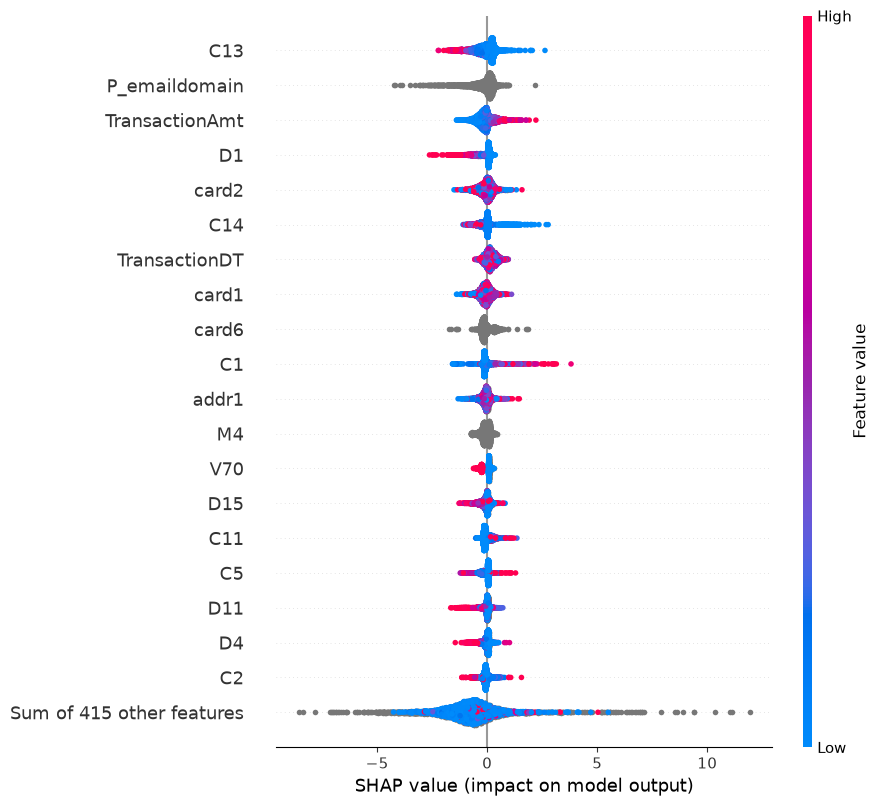

In [21]:
# Vue globale : pour chaque feature (lignes, triées par importance), chaque point est
# une transaction ; position = contribution au score, couleur = valeur de la feature.
shap.plots.beeswarm(sv, max_display=20)

In [22]:
# Rang de nos features construites : importance = moyenne des |valeurs SHAP|.
imp = pd.Series(np.abs(sv.values).mean(axis=0), index=X_sample.columns).sort_values(ascending=False)
imp.index.get_loc('has_3dec') + 1, imp.index.get_loc('hour') + 1, len(imp)

(302, 33, 434)

In [23]:
# hour : 33e/434 (top 8 %). has_3dec : 302e/434 — paradoxe apparent pour une feature
# qui concentrait 35 % des fraudes. Explication : SHAP mesure la contribution
# MARGINALE ; l'info "devise convertie" est déjà portée en pièces détachées par
# TransactionAmt et ses voisines, et SHAP répartit le crédit entre colonnes corrélées
# (cf. 04 : corrélation partout). L'ablation de 03 (+1,5 pt PR-AUC, -1 830 EUR)
# reste la preuve causale que le duo has_3dec + hour apporte — probablement surtout hour.


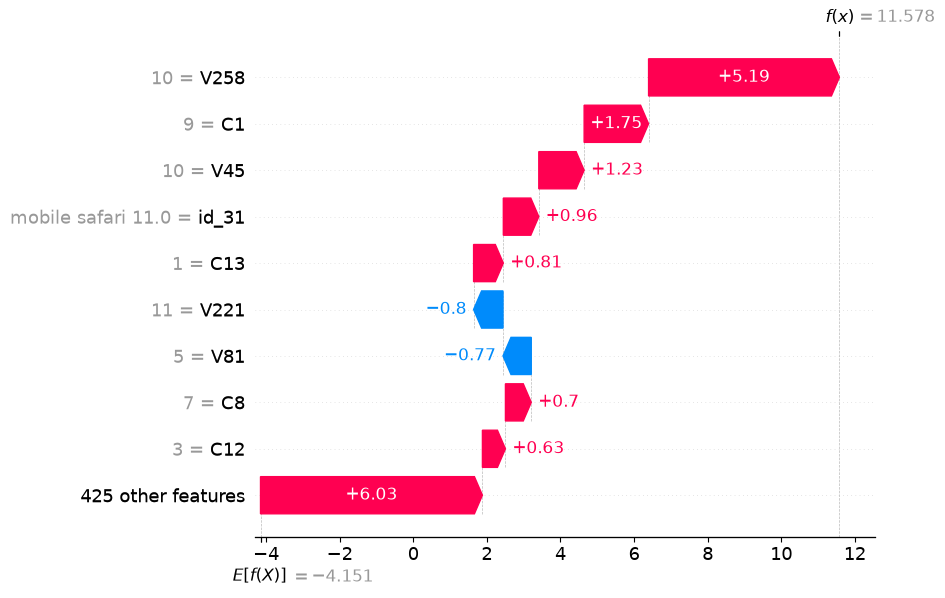

In [24]:
# Explication locale : la transaction la plus suspecte de l'échantillon, décomposée.
# La réponse à "pourquoi CETTE transaction est bloquée", feature par feature.
probs_sample = model.predict_proba(X_sample)[:, 1]
shap.plots.waterfall(sv[np.argmax(probs_sample)])

In [25]:
# Lecture : départ à -4,15 (base), arrivée f(x) = 11,58 -> sigmoide ~ 0,99999.
# V258=10 apporte +5,19 à elle seule ; le reste est une accumulation d'indices
# concordants (C1, V45, id_31 = vieux navigateur mobile, + 425 features pour +6,03).
# Limite : V258 est anonymisée (Vesta) — on sait QUELLE colonne condamne,
# pas toujours ce qu'elle signifie métier.

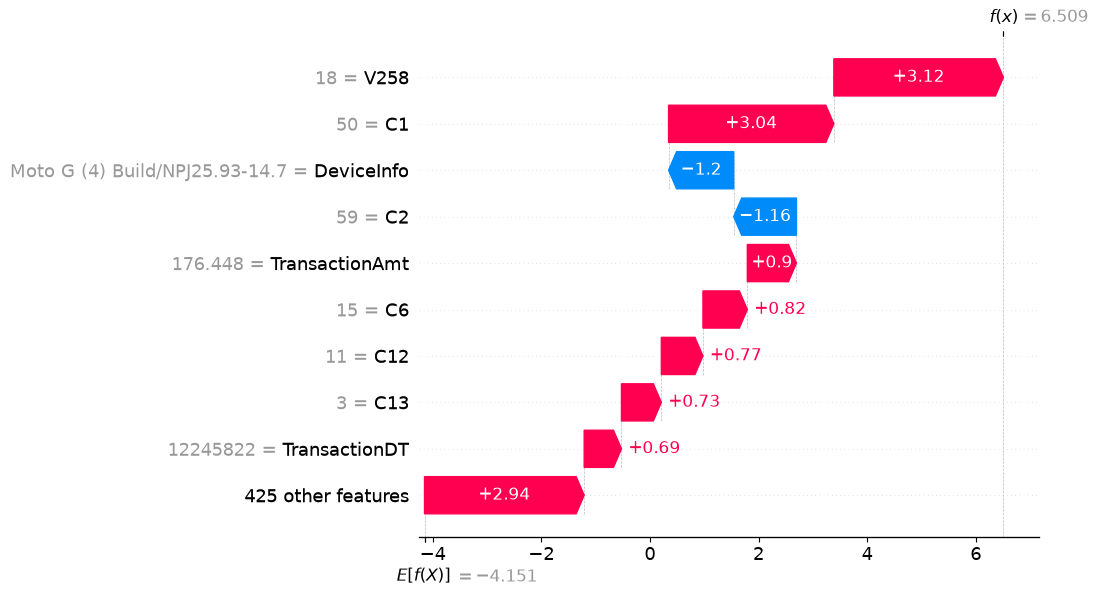

In [26]:
# Le "client furieux" : la transaction LÉGITIME la plus mal notée de l'échantillon.
# C'est à lui qu'il faut savoir répondre — le waterfall EST la réponse.
y_sample = y_valid.loc[X_sample.index]
fp_pos = np.argmax(np.where(y_sample.values == 0, probs_sample, -1))
shap.plots.waterfall(sv[fp_pos])

In [27]:
# Conclusion SHAP : le modèle est désormais auditable — globalement (beeswarm :
# importance très répartie sur des centaines de colonnes ; cartes récentes et vieux
# navigateurs = profils à risque appris seuls) et localement (waterfall : la
# contribution de chaque colonne au score d'UNE transaction — la réponse au client
# bloqué et au régulateur). Nos features : hour 33e/434 (top 8 %) ; has_3dec 302e,
# redondante en marginal mais utile en ablation (cf. 03). Limite structurelle : sur
# la transaction la plus suspecte comme sur le pire faux positif, les plus grosses
# contributions viennent de colonnes Vesta anonymisées (V258, C1) — on sait QUELLE
# colonne décide, pas toujours ce qu'elle signifie métier.